Mean Anomaly

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

In [2]:
# K = const = sqrt(G*M_SUN)
k = 0.017202098950000 #AU^3/2 days^-1 
#### TABLE 4 ####
#Estimated Values
a_est = 2.947 #AU
omega_est = 80.65 #deg
i_est = 10.56 #deg
e_est = 0.125
w_est = 63.20 #deg
tau_est = 2454833 #Julian Day
################
#True Values
a = 2.766 #AU
omega = 80.72 #deg
i = 10.61 #deg
e = 0.079
w = 73.12 #deg
tau = 2454868 #Julian Day
################

def newton_integrate(k,e,a,tau,dt=0.01):
    # p = period [days]
    # n = mean motion [rad/day]
    # M = mean anomaly [rad]
    # E = eccentric anomaly [rad]
    # t = current epoch [JD]
    # tau = epoch of perihelion [JD]
    # dt = time step [days]

    n = k*a**(-3/2)

    p = (2*np.pi)/n

    # M as a function of E
    def M_E(E):
        return E - e*np.sin(E)
    
    # M as a function of t
    t = np.arange(tau,tau + 1.5*p,dt)
    M = n*(t-tau)

    print(f"Using {len(t)-1} steps with time step {dt}")
    
    # Initialize arrays to store solution. Set E_0 = M for first iteration
    E_values = M.copy()
    M_values = E_values.copy()

    for j in range(1,len(t)):
        M_values[j-1] = M_E(E_values[j-1])
        E_values[j] = E_values[j-1] +(M[j-1] - M_E(E_values[j-1]))/(1-e*np.cos(E_values[j-1]))
    return E_values, M_values, t

#True Orbit
E_true, M_true, t_true = newton_integrate(k, e, a, tau)
print(M_true)
#Estimated Orbit
E_est, M_est, t_est = newton_integrate(k, e_est, a_est, tau_est)


Using 252039 steps with time step 0.01
[0.00000000e+00 0.00000000e+00 3.73941071e-05 ... 9.42466119e+00
 9.42469858e+00 9.42477337e+00]
Using 277178 steps with time step 0.01


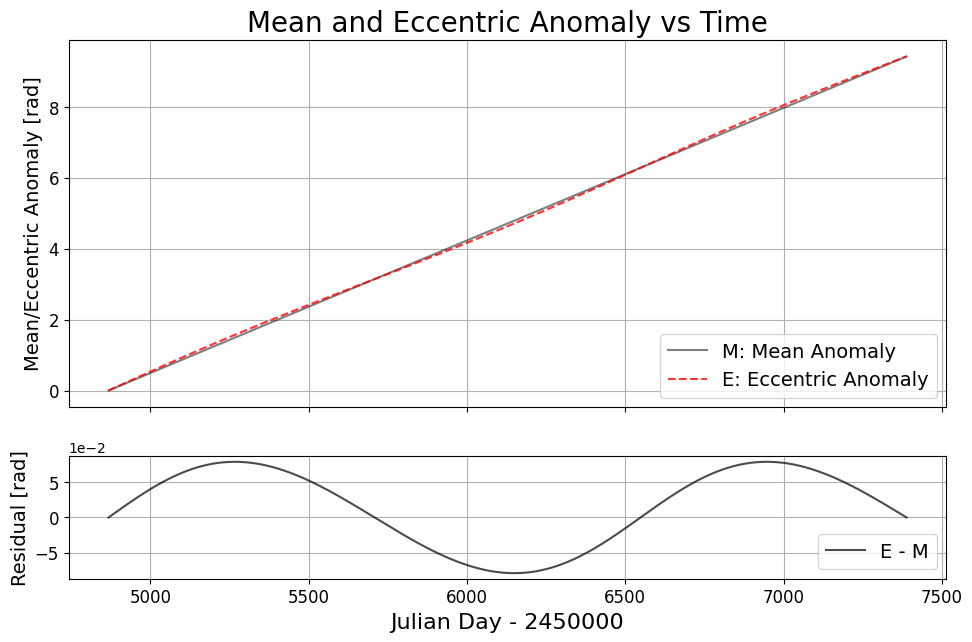

In [3]:
T = t_true - 2450000 
r = a*(1-e*np.cos(E_true)) #eq 22
nu = 2*np.arctan(np.sqrt((1+e)/(1-e))*np.tan(E_true/2)) #eq 31
theta = nu + np.deg2rad(w) #Look above eq 36

T_est = t_est - 2450000 
r_est = a_est*(1-e_est*np.cos(E_est)) #eq 22
nu_est = 2*np.arctan(np.sqrt((1+e_est)/(1-e_est))*np.tan(E_est/2)) #eq 31
theta_est = nu_est + np.deg2rad(w_est) #Look above eq 36

gr = 1.618033988749
scale = 7

f, (a0, a1) = plt.subplots(nrows=2, 
             sharex=True,
             #subplot_kw=dict(frameon=False), 
             figsize = (scale*gr, scale),
             gridspec_kw={'height_ratios': [3, 1]})
#Plot 1
a0.plot(T, M_true, "-", color = 'k', alpha = 0.5, label = 'M: Mean Anomaly')
a0.plot(T, E_true, "--", color = 'r', alpha = 0.8, label = 'E: Eccentric Anomaly')
a0.set_ylabel("Mean/Eccentric Anomaly [rad]", size = 14)
a0.set_title("Mean and Eccentric Anomaly vs Time",size = 20)
a0.legend(loc = 4, prop={'size': 14})
a0.tick_params(axis='y', labelsize=12)
a0.grid()

#Plot 2
a1.plot(T, E_true-M_true, "-", color = 'k', alpha = 0.7, label = 'E - M')
a1.set_xlabel("Julian Day - 2450000", size = 16)
a1.set_ylabel("Residual [rad]", size = 14)
a1.grid()
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
a1.tick_params(axis='x', labelsize=12)
a1.tick_params(axis='y', labelsize=12)
a1.legend(loc = 4,prop={'size': 14})
plt.show()

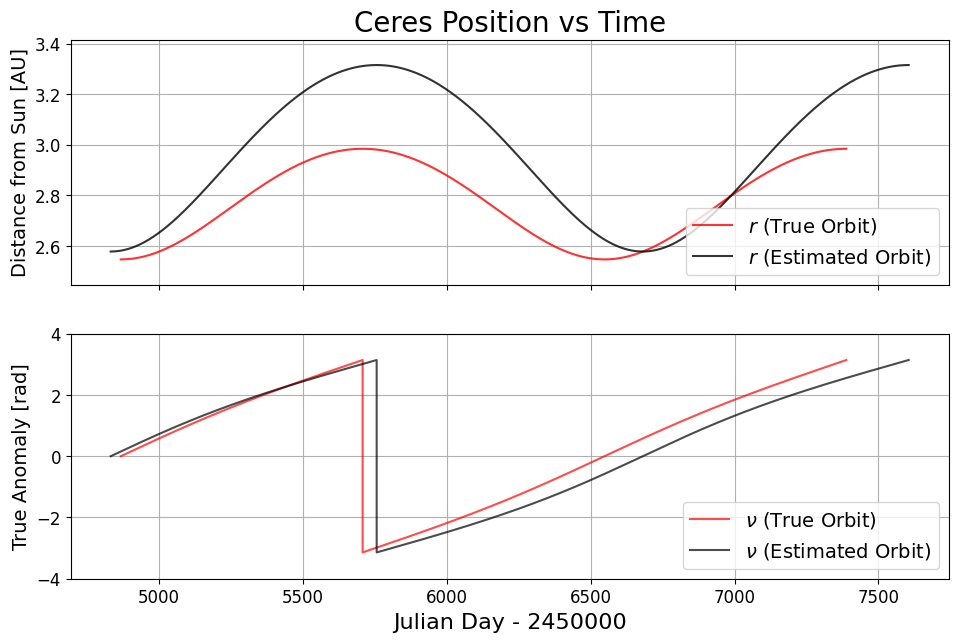

In [4]:
f, (a0, a1) = plt.subplots(nrows=2, 
             sharex=True,
             #subplot_kw=dict(frameon=False), 
             figsize = (scale*gr, scale),
             gridspec_kw={'height_ratios': [1, 1]})
#Plot 1
a0.plot(T, r, color = 'r', alpha = 0.8, label = r"$r$ (True Orbit)")
a0.plot(T_est, r_est, color = 'k', alpha = 0.8, label = r"$r$ (Estimated Orbit)")
a0.set_ylabel("Distance from Sun [AU]", size = 14)
a0.set_title("Ceres Position vs Time",size = 20)
a0.legend(loc = 4, prop={'size': 14})
a0.tick_params(axis='y', labelsize=12)
a0.grid()
a0.set_ylim(np.min(r) - 0.1,np.max(r_est) + 0.1)

#Plot 2
a1.plot(T, nu, "-", color = 'r', alpha = 0.7, label = r'$\nu$ (True Orbit)')
a1.plot(T_est, nu_est, "-", color = 'k', alpha = 0.7, label = r'$\nu$ (Estimated Orbit)')
a1.set_xlabel("Julian Day - 2450000", size = 16)
a1.set_ylabel("True Anomaly [rad]", size = 14)
a1.grid()
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
a1.tick_params(axis='x', labelsize=12)
a1.tick_params(axis='y', labelsize=12)
a1.legend(loc = 4,prop={'size': 14})
a1.set_ylim(-4,4)

plt.show()

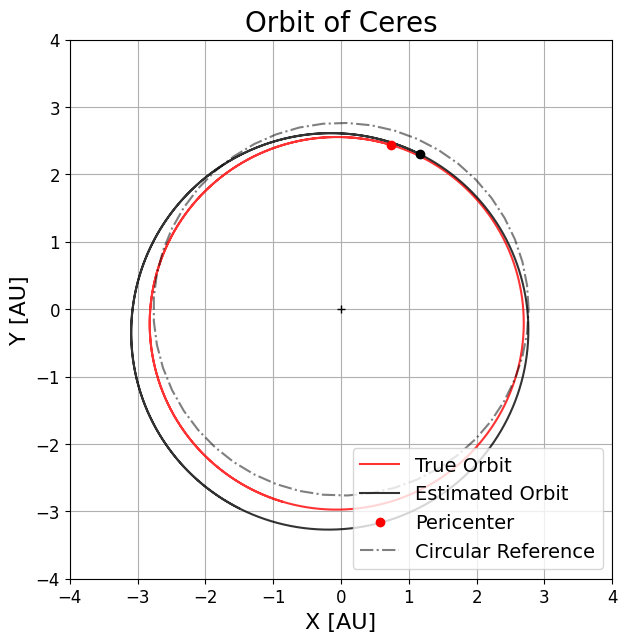

In [5]:
plt.figure(figsize=(scale,scale))

plt.plot(0, 0,'+', color = 'k')

plt.plot(r*np.cos(theta), r*np.sin(theta), color = 'r', alpha = 0.8, label = "True Orbit")

plt.plot(r_est*np.cos(theta_est), r_est*np.sin(theta_est), alpha = 0.8, color = 'k', label = "Estimated Orbit")

plt.plot(r[0]*np.cos(theta[0]), r[0]*np.sin(theta[0]), 'o', color = 'r', label = "Pericenter")
plt.plot(r_est[0]*np.cos(theta_est[0]), r_est[0]*np.sin(theta_est[0]), 'o', color = 'k')

phi = np.linspace(0, 2*np.pi)
plt.plot(a*np.cos(phi), a*np.sin(phi), '-.', color = 'k', alpha = 0.5, label = "Circular Reference")

plt.xlim(-4,4)
plt.ylim(-4,4)
plt.xlabel("X [AU]", size = 16)
plt.ylabel("Y [AU]", size = 16)
plt.grid()
plt.title("Orbit of Ceres", size = 20)
plt.legend(loc = 4,prop={'size': 14})
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.show()

2.5 Ecliptic & Equatorial Coordinates

In [6]:
### Ceres ###
# *******************************************************************************
# Date_________JDUT     R.A.___(ICRF)___DEC     ObsEcLon    ObsEcLat
# ******************************************************************
# $$SOE
# 2454702.500000000     124.86809  23.75270  121.7592660   4.0625672
# 2454703.500000000     125.33031  23.69072  122.1865452   4.0992600
# 2454704.500000000     125.79168  23.62790  122.6133860   4.1361611
# $$EOE
# *******************************************************************************

def celestial_to_ecliptic_cart(ra,dec):
    X_eq = np.cos(np.deg2rad(ra))*np.cos(np.deg2rad(dec))
    Y_eq = np.sin(np.deg2rad(ra))*np.cos(np.deg2rad(dec))
    Z_eq = np.sin(np.deg2rad(dec))
    # print("Ecliptic Cartesian Coordinates (deg): ", np.rad2deg(X_eq),np.rad2deg(Y_eq),np.rad2deg(Z_eq))
    epsilon = np.deg2rad(23.43929111)
    x = X_eq
    y = Y_eq*np.cos(epsilon) + Z_eq*np.sin(epsilon)
    z = -Y_eq*np.sin(epsilon) + Z_eq*np.cos(epsilon)
    # print("Unit Vectors in Ecliptic Frame (rad): ", x,y,z)
    return x,y,z

# Given three times returns velocity at 2nd time
def s_dot(times,coords):
    # using taylor series
    tau_1 = times[1] - times[0]
    tau_3 = times[2] - times[1]
    return (tau_3*(coords[1]-coords[0]))/(tau_1*(tau_1+tau_3)) + (tau_1*(coords[2]-coords[1]))/(tau_3*(tau_1+tau_3))

# Given three times returns acceleration at 2nd time
def s_dot_dot(times,coords):
    tau_1 = times[1] - times[0]
    tau_3 = times[2] - times[1]
    return 2*(coords[2] - coords[1])/(tau_3*(tau_1+tau_3)) - 2*(coords[1]-coords[0])/(tau_1*(tau_1+tau_3))

def rho_solver(r_guess, R, s, s_dot, s_dot_dot, accuracy = 1e-6, max_itr=10**6, inc=0.00001):
    def rho(r,R,s,s_dot,s_dot_dot):
        return k**2*(1/np.linalg.norm(R[1])**3 - 1/r**3)*(np.dot(s_dot,np.cross(R[1],s[1])))/(np.dot(s_dot,np.cross(s_dot_dot,s[1])))
    r = r_guess
    dr = inc
    for i in range(0,max_itr):
        rho_old = rho(r, R, s, s_dot, s_dot_dot)
        r+=dr
        rho_new = rho(r, R, s, s_dot, s_dot_dot)
        d_rho = np.abs(rho_new) - np.abs(rho_old)
        if d_rho <= accuracy:
            print(f"Solved rho({r}) = {rho_new} in {i} iterations, with accuracy {d_rho}")
            return rho_new
def rho_dot(r,R,s,s_dot,s_dot_dot):
    return (k**2/2)*(1/np.linalg.norm(R[1])**3 - 1/np.linalg.norm(r)**3)*(np.dot(s_dot_dot,np.cross(R[1],s[1])))/(np.dot(s_dot_dot,np.cross(s_dot,s[1])))
def r(rho,R,s):
    return np.sqrt(rho**2 + np.linalg.norm(R[1])**2 + 2*rho*np.dot(s[1],R[1]))
def r_dot(rho,rho_dot,R_dot, s, s_dot):
    return R_dot[1] + rho*s_dot + rho_dot*s[1]

######################## Proserpina (Tom's obs and Ephemeris sun-earth vector) ########################
R_pros = np.array([[-4.839943788688217e-01, 8.567315077911066e-01, -2.430059010880054e-05],
                   [-4.993079108676164e-01, 8.480006311211998e-01, -2.466818936373878e-05],
                   [-5.297936568478157e-01, 8.295212676726603e-01, -2.517397903282655e-05],
                   [-5.712949145475025e-01, 8.018594933188263e-01, -2.501185296539947e-05]])

R_dot_pros = np.array([[-1.526643949321232e-02, -8.525858896020743e-03, -3.855835353970162e-07],
                       [-1.511257153420666e-02, -8.794493842540710e-03, -3.374110866457986e-07],
                       [-1.478571027653773e-02, -9.328745251113220e-03, -1.391122123137612e-07],
                       [-1.429468504521881e-02, -1.005377067836366e-02, 2.646232556130592e-07]])

pros_jd = np.array([2455946.811041667, 2455947.819178241, 2455949.858240741, 2455952.711863426])

print("Proserpina")
print("------------------------")

# Get unit vectors from ra, dec
#coords_prop_ra_dec = np.array([[81.029, 26.981],[80.880,26.967],[80.631,26.940],[80.339,26.908]])
coords_prop_ra_dec = np.array([[81.22811, 26.99100], [81.08767, 26.97887], [80.82548, 26.95393], [80.50876, 26.91860]])

s_pros = np.array([celestial_to_ecliptic_cart(*coord) for coord in coords_prop_ra_dec])

# Unit vector derivatives
s_dot_pros = s_dot(pros_jd,s_pros)
s_dot_dot_pros = s_dot_dot(pros_jd,s_pros)

# Solve for rho, rho_dot, r, r_dot
rho_pros = rho_solver(2.5, R_pros, s_pros, s_dot_pros, s_dot_dot_pros)
rho_dot_pros = rho_dot(rho_pros, R_pros, s_pros, s_dot_pros, s_dot_dot_pros)
r_pros = r(rho_pros, R_pros, s_pros)
r_pros_vec = R_pros[1] + rho_pros*s_pros[1]
r_dot_pros = r_dot(rho_pros, rho_dot_pros, R_dot_pros, s_pros, s_dot_pros)

print("rho: ", rho_pros)
print("rho_dot:", rho_dot_pros)
print("r: ", r_pros_vec)
print("|r|: ", r_pros)
print("r_dot: ", r_dot_pros)
print("|r_dot|: ", np.linalg.norm(r_dot_pros))
print("s: ", s_pros[0])
print("s_dot: ", s_dot_pros)
print("s_dot_dot: ", s_dot_dot_pros)
print("------------------------")

######################## Ceres ##########################################
R_ceres = np.array([[0.8849747143832394, -0.4888376660952258, 4.464941484204715E-06],
     [0.8928924150493818, -0.4737757563214451, 4.401526303436856E-06],
     [0.9005547316019139, -0.4585763814046491, 4.482870706977596E-06]])

R_dot_ceres = np.array([[8.044450672656130e-03, 1.499181301004085e-02, -1.409324171451239e-07],
         [7.790478517409600e-03, 1.513133074608821e-02, 1.194754466248652e-08],
         [7.533687958968585e-03, 1.526671772306336e-02, 1.469642152045375e-07]])

# Taken from NASA ephemeris apparent ra, dec
ceres_jd = np.array([2454702.5, 2454703.5, 2454704.5])
coords_ceres_ra_dec = np.array([[124.99501, 23.72690], [125.45718,23.66456], [125.91851, 23.60140]])

print("Ceres")
print("----------------------")
s_ceres = np.array([celestial_to_ecliptic_cart(*coord) for coord in coords_ceres_ra_dec])

# Unit vector derivatives solved using taylor series expansions
s_dot_ceres = s_dot(ceres_jd,s_ceres)
s_dot_dot_ceres = s_dot_dot(ceres_jd,s_ceres)

# Solve for rho, rho_dot, r, r_dot
rho_ceres = rho_solver(2.0, R_ceres, s_ceres, s_dot_ceres, s_dot_dot_ceres)
rho_dot_ceres = rho_dot(rho_ceres, R_ceres, s_ceres, s_dot_ceres, s_dot_dot_ceres)
r_ceres = r(rho_ceres, R_ceres, s_ceres)
r_ceres_vec = R_ceres[1] + rho_ceres*s_ceres[1]
r_dot_ceres = r_dot(rho_ceres, rho_dot_ceres, R_dot_ceres, s_ceres, s_dot_ceres)
r_dot_mag_ceres = np.linalg.norm(r_dot_ceres)

print("rho: ", rho_ceres)
print("rho_dot:", rho_dot_ceres)
print("r: ", r_ceres_vec)
print("|r|: ", r_ceres)
print("r_dot: ", r_dot_ceres)
print("|r_dot|: ", r_dot_mag_ceres)
print("s: ", s_ceres[0])
print("s_dot: ", s_dot_ceres)
print("s_dot_dot: ", s_dot_dot_ceres)
print("------------------------")


#### FROM NASA EPHEMERIS TO CHECK VALUES [AU] ###
# rho_ceres = 3.42618221672372
# rho_dot_ceres = -0.0071286699949
# r_dot_ceres = 0.01099817223

# rho_pros = 2.00939831254757
# rho_dot_pros = 0.008192355592398
# r_dot_pros = 0.00982891772884
# r_pros  = 2.84469275723986



Proserpina
------------------------
Solved rho(2.7818400000018464) = 2.001919587660887 in 28183 iterations, with accuracy 9.99994798522863e-07
rho:  2.001919587660887
rho_dot: 0.007882614619803788
r:  [-0.22291624  2.82633901  0.1321379 ]
|r|:  2.838193838123361
r_dot:  [-0.00981832 -0.00158113  0.00035937]
|r_dot|:  0.009951313054794233
s:  [0.13589024 0.9885167  0.06609521]
s_dot:  [ 2.10095687e-03 -2.87924325e-04 -8.02641200e-05]
s_dot_dot:  [-1.08290903e-04  1.12790162e-05 -7.12670452e-06]
------------------------
Ceres
----------------------
Solved rho(3.2389100000081164) = 3.4440112293815144 in 123890 iterations, with accuracy 9.999911538827178e-07
rho:  3.4440112293815144
rho_dot: -0.007501520870269681
r:  [-0.93696184  2.43349357  0.24623968]
|r|:  2.6192408124962427
r_dot:  [-0.00980908 -0.00497368  0.00166941]
|r_dot|:  0.011123962047325344
s:  [-0.52502888  0.84812959  0.07085812]
s_dot:  [-0.00626747 -0.003999    0.00064045]
s_dot_dot:  [ 3.69791270e-05 -4.30146418e-05  3.8